# Laboratorium: regresja liniowa na danych Melbourne Housing

## Wstęp

Celem laboratorium jest zbudowanie modelu przewidującego **ceny domów w Melbourne** na podstawie ich lokalizacji, wielkości, liczby pokoi, wieku budynku i kilku innych cech. Po drodze przejdziesz przez tworzenia modelu dla danych tabelarycznych:

1. przygotowanie środowiska z użyciem `uv`,
2. eksploracyjną analizę danych (EDA) i ich czyszczenie,
3. regresję liniową wraz z  przetwarzaniem danych w scikit-learn,
4. regularyzację (ridge, LASSO, ElasticNet),
5. dobór hiperparametrów z walidacją skrośną.



### Uwagi

- kod uzupełniasz w miejscach oznaczonych `# TODO`,
- pod większością zadań znajdują się asercje (`assert`), które pomogą Ci sprawdzić rozwiązanie; jeżeli nie przechodzą, a uważasz, że rozwiązanie jest poprawne, opisz problem w komentarzu,
- część zadań wymaga odpowiedzi pisemnej w komórce oznaczonej **Odpowiedź:** - krótko, 2–4 zdania wystarczą,
- pamiętaj o tytułach i opisach osi na wykresach,
- nie zmieniaj nazw zmiennych, z których korzystają asercje i kolejne zadania.


## Część 1. Konfiguracja środowiska z `uv` 

[`uv`](https://docs.astral.sh/uv/) to szybki menedżer pakietów i środowisk dla Pythona, napisany w Ruście przez firmę Astral. Zastępuje jednocześnie `pip`, `venv`, `pip-tools`, `pyenv` i w dużej mierze `poetry`. Najważniejsze pliki projektu to:

- **`pyproject.toml`** - opis projektu i jego zależności (np. `scikit-learn>=1.6`),
- **`uv.lock`** - plik blokady (*lockfile*) z **dokładnymi** wersjami wszystkich bibliotekgenerowany automatycznie,
- **`.venv/`** - lokalne środowisko wirtualne projektu; nie trafia do repozytorium,
- **`.python-version`** - wersja Pythona, której ma używać projekt; `uv` sam ją pobierze, jeśli nie masz jej w systemie.

Projekt laboratorium jest **już przygotowany** - `pyproject.toml` i `uv.lock` są w repozytorium. Nie musisz niczego tworzyć ani dodawać, wystarczy odtworzyć środowisko.

### Krok 1. Zainstaluj `uv` (jednorazowo)

```bash
# Linux / macOS
curl -LsSf https://astral.sh/uv/install.sh | sh

# Windows (PowerShell)
powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"
```

Zamknij i otwórz ponownie terminal, a potem sprawdź instalację: `uv --version`.

### Krok 2. Pobierz projekt i odtwórz środowisko

```bash
git clone <adres-repozytorium>      # albo pobierz i rozpakuj archiwum ZIP
cd lab01_regresja
uv sync
```

`uv sync` czyta `pyproject.toml` i `uv.lock`, w razie potrzeby pobiera Pythona 3.12, tworzy katalog `.venv/` i instaluje w nim **dokładnie te same wersje** bibliotek, z którymi przygotowano laboratorium. Dzięki temu wszyscy pracują w identycznym środowisku.

### Krok 3. Uruchom notebook

```bash
uv run jupyter lab
```

`uv run` uruchamia polecenie w środowisku projektu bez ręcznej aktywacji `.venv`. W **VS Code** otwórz folder projektu, a następnie w notebooku wybierz kernel z `.venv` (Python 3.12).


### Dane

Plik `data/melb_data.csv` (zbiór [Melbourne Housing Snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot) z Kaggle, autor: Tony Pino, licencja CC BY-NC-SA 4.0) jest dołączony do repozytorium, więc nie trzeba go pobierać.

### Google Colab

Jeżeli pracujesz w Colabie, prześlij do katalogu `/content` plik `melb_data.csv` oraz `requirements.txt`, zmień ścieżkę `DATA_PATH` poniżej i odkomentuj komórkę z instalacją. Plik `requirements.txt` został wyeksportowany z `uv.lock`, więc zawiera te same wersje bibliotek co środowisko lokalne. Po instalacji zrestartuj sesję (*Runtime → Restart session*).

In [ ]:
# odkomentuj i uruchom, jeżeli korzystasz z Google Colab
# !pip install -r requirements.txt

### Importy i konfiguracja

Ustawiamy globalnie `transform_output="pandas"` ([dokumentacja](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_set_output.html)), dzięki czemu transformatory scikit-learn zwracają `DataFrame` z nazwami kolumn zamiast tablic NumPy. Ułatwia to debugowanie i interpretację współczynników modelu.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

sklearn.set_config(transform_output="pandas")

RANDOM_STATE = 42
DATA_PATH = "data/melb_data.csv"  # w Colabie: "/content/melb_data.csv"
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={"Lattitude": "Latitude", "Longtitude": "Longitude"}) # fix typos

## Część 2. Eksploracyjna analiza danych i przygotowanie danych do modelowania

Zbiór **Melbourne Housing Snapshot** zawiera dane o sprzedaży nieruchomości w Melbourne z lat 2016–2017. Zmienną docelową jest cena `Price` w dolarach australijskich (AUD), więc mamy do czynienia z **regresją**.

| Kolumna | Opis |
|---|---|
| `Suburb` | dzielnica |
| `Address` | adres |
| `Rooms` | liczba pokoi |
| `Type` | typ: `h` - dom, `u` - mieszkanie (*unit*), `t` - szeregowiec (*townhouse*) |
| `Price` | **cena sprzedaży (zmienna docelowa)** |
| `Method` | sposób sprzedaży (aukcja, sprzedaż prywatna itp.) |
| `SellerG` | agencja nieruchomości |
| `Date` | data sprzedaży |
| `Distance` | odległość od centrum (CBD) w km |
| `Postcode` | kod pocztowy |
| `Bedroom2` | liczba sypialni (z innego źródła danych) |
| `Bathroom`, `Car` | liczba łazienek i miejsc parkingowych |
| `Landsize`, `BuildingArea` | powierzchnia działki i budynku w m² |
| `YearBuilt` | rok budowy |
| `CouncilArea`, `Regionname` | jednostka samorządowa i region |
| `Lattitude`, `Longtitude` | współrzędne geograficzne (literówki są w oryginalnych danych - poprawimy je) |
| `Propertycount` | liczba nieruchomości w dzielnicy |

In [2]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [3]:
df.columns

Index(['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG',
       'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Latitude',
       'Longitude', 'Regionname', 'Propertycount'],
      dtype='str')

### Dlaczego zaczynamy od eksploracji danych?

Zanim zbudujemy jakikolwiek model,powinniśmy ustalić:

1. **Jak wygląda zmienna docelowa.** Od jej rozkładu zależy, co model ma przewidywać (cenę czy jej logarytm) i którą metrykę wybrać.
2. **Jakiej jakości są dane.** Braki, wartości niemożliwe i obserwacje odstające trzeba obsłużyć, zanim trafią do modelu - np. model liniowy nie przyjmie `NaN`, a pojedyncze outliery potrafią mocno przesunąć jego wagi.
3. **Jakie zależności są w danych.** Model liniowy potrafi wyrazić tylko pewien rodzaj zależności. Jeżeli wiemy z góry, czego w danych nie uchwyci, łatwiej zinterpretujemy jego wyniki i błędy.

**Każda decyzja podjęta w tej części (co usunąć, co uzupełnić, co przekształcić) zostanie później zapisana w potoku przetwarzania danych w części 3.**

Pierwszy krok EDA to zawsze sprawdzenie rozmiaru danych, typów kolumn i wartości brakujących. Przydatne narzędzia Pandasa: `.shape`, `.info()`, `.describe()`, `.isna()`, `.select_dtypes()`, `.nunique()`, `.value_counts()`, `.groupby()`.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  str    
 1   Address        13580 non-null  str    
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  str    
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  str    
 6   SellerG        13580 non-null  str    
 7   Date           13580 non-null  str    
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  str    
 17  Latitude       13580 non-null  float64
 18  Longitude      13

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997e+00,0.955748,1.00000,2.000000,3.000000,3.000000e+00,1.000000e+01
Price,13580.0,1.075684e+06,639310.724296,85000.00000,650000.000000,903000.000000,1.330000e+06,9.000000e+06
Distance,13580.0,1.013778e+01,5.868725,0.00000,6.100000,9.200000,1.300000e+01,4.810000e+01
Postcode,13580.0,3.105302e+03,90.676964,3000.00000,3044.000000,3084.000000,3.148000e+03,3.977000e+03
Bedroom2,13580.0,2.914728e+00,0.965921,0.00000,2.000000,3.000000,3.000000e+00,2.000000e+01
Bathroom,13580.0,1.534242e+00,0.691712,0.00000,1.000000,1.000000,2.000000e+00,8.000000e+00
Car,13518.0,1.610075e+00,0.962634,0.00000,1.000000,2.000000,2.000000e+00,1.000000e+01
Landsize,13580.0,5.584161e+02,3990.669241,0.00000,177.000000,440.000000,6.510000e+02,4.330140e+05
BuildingArea,7130.0,1.519676e+02,541.014538,0.00000,93.000000,126.000000,1.740000e+02,4.451500e+04
YearBuilt,8205.0,1.964684e+03,37.273762,1196.00000,1940.000000,1970.000000,1.999000e+03,2.018000e+03


Funkcja pomocnicza `plot_distribution` do rysowania rozkładów - przyda się kilka razy w trakcie laboratorium. Rysuje histogram oraz średnią i medianę jako pionowe linie.

In [6]:
def plot_distribution(values, title, xlabel, bins=50):
    values = pd.Series(values)
    mean, median = values.mean(), values.median()
    plt.figure(figsize=(8, 4))
    plt.hist(values, bins=bins, color="tab:blue", alpha=0.7)
    plt.axvline(mean, color="tab:red", linestyle="--", label=f"średnia: {mean:,.2f}")
    plt.axvline(median, color="tab:green", linestyle="--", label=f"mediana: {median:,.2f}")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Liczba nieruchomości")
    plt.legend()
    plt.show()

### Braki danych i skośność zmiennej docelowej

**Braki danych.** W przyadku braku danych mamy do wyboru takie możliwości:
- *usunąć kolumnę* - tracimy całą informację z cechy, nawet jeśli jest bardzo wartościowa,
- *usunąć wiersze z brakami* - tracimy obserwacje, jeśli braki dotyczą dużej części danych, tracimy dużo, a jeśli braki nie są losowe (np. częściej dotyczą starszych domów), dodatkowo zniekształcamy próbę.
- *uzupełnić (imputacja)* - zachowujemy dane, ale wartość jako przybliżenie (średnia, mediana, moda, kNN, MICE).

W tym laboratorium **uzupełniamy braki** medianą i dodajemy kolumnę-wskaźnik informującą model, że wartość była uzupełniona (zrobimy to w zadaniu 4). Mediana zamiast średniej, bo jest odporna na wartości odstające.

**Skośność.** Regresja liniowa minimalizuje błąd średniokwadratowy (MSE). Jeżeli rozkład ceny jest skośny, kilka bardzo drogich nieruchomości daje ogromne błędy kwadratowe i to one najbardziej wpływją na wagi modelu. Logarytm sprawia, że rozkład staje się symetryczny. Jest też drugi powód: czynniki cenotwórcze działają zwykle **procentowo** (multiplikatywnie a nie addydywnie: dodatkowy pokój podnosi cenę o kilka procent, a nie o stałą kwotę), a logarytm zamienia efekty mnożące się w efekty dodające się - czyli w to, co potrafi wyrazić model liniowy. Dlatego model będzie przewidywał logarytm ceny.

W zadaniu 1 sprawdzisz czy powyższe problemy dotyczą naszych danych.

### Zadanie 1 (1 punkt) - przegląd danych

1. Przypisz liczbę próbek i liczbę cech do zmiennych `n_samples` i `n_features`. Pamiętaj, że `Price` to zmienna docelowa, a nie cecha.
2. Utwórz listy nazw kolumn numerycznych i kategorycznych (bez `Price`): `numerical_cols` i `categorical_cols`.
3. Oblicz odsetek wartości brakujących w każdej kolumnie. Zostaw tylko kolumny z brakami, posortuj malejąco i zapisz w `missing_pct` (`pd.Series`). Narysuj poziomy wykres słupkowy (`.plot.barh()`).
4. Narysuj funkcją `plot_distribution()` rozkład `Price` oraz `np.log1p(Price)`. Oblicz skośność (`.skew()`) obu rozkładów i zapisz w `price_skew` oraz `log_price_skew`.
5. Odpowiedz krótko, korzystając ze swoich wyników:
   - które kolumny wymagają uzupełniania braków? Czy któraś ma tyle braków, że rozważyłbyś jej usunięcie - i co byś wtedy stracił?
   - o ile zmniejszyła się skośność po logarytmowaniu i co to oznacza dla funkcji kosztu MSE?

Próbki: 13580, cechy: 20
Numeryczne: ['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Latitude', 'Longitude', 'Propertycount']
Kategoryczne: ['Suburb', 'Address', 'Type', 'Method', 'SellerG', 'Date', 'CouncilArea', 'Regionname']
BuildingArea    47.50
YearBuilt       39.58
CouncilArea     10.08
Car              0.46
dtype: float64


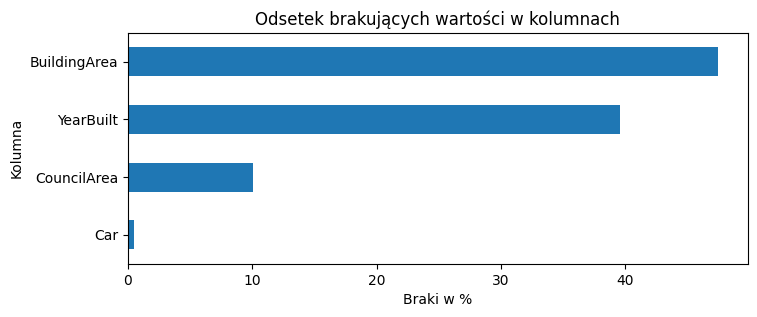

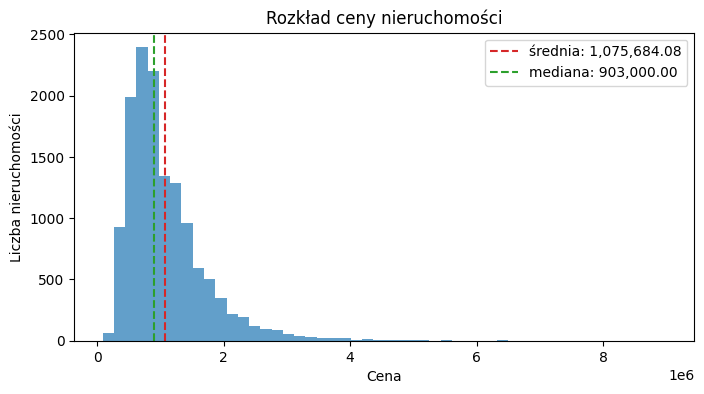

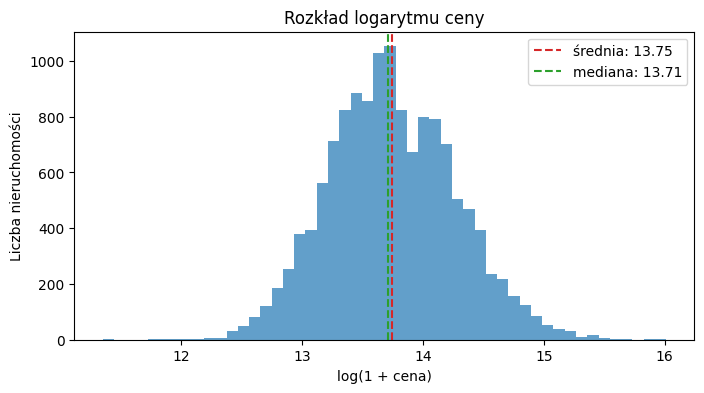

Skośność ceny: 2.240
Skośność log-ceny: 0.181


In [9]:
# TODO: liczba próbek i cech, listy kolumn
n_samples = df.shape[0]
n_features = df.shape[1] - 1

features = df.drop(columns="Price")
numerical_cols = features.select_dtypes(include="number").columns.tolist()
categorical_cols = features.select_dtypes(exclude="number").columns.tolist()

print(f"Próbki: {n_samples}, cechy: {n_features}")
print("Numeryczne:", numerical_cols)
print("Kategoryczne:", categorical_cols)

# TODO: procent wartości brakujących i wykres
missing_pct = df.isna().mean() * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)
print(missing_pct.round(2))

ax = missing_pct.plot.barh(figsize=(8, 3))
ax.invert_yaxis()  # największe braki na górze
ax.set_title("Odsetek brakujących wartości w kolumnach")
ax.set_xlabel("Braki w %")
ax.set_ylabel("Kolumna")
plt.show()

# TODO: rozkład ceny i log-ceny, skośność
plot_distribution(df["Price"], "Rozkład ceny nieruchomości", "Cena")
plot_distribution(np.log1p(df["Price"]), "Rozkład logarytmu ceny", "log(1 + cena)")

price_skew = df["Price"].skew()
log_price_skew = np.log1p(df["Price"]).skew()
print(f"Skośność ceny: {price_skew:.3f}")
print(f"Skośność log-ceny: {log_price_skew:.3f}")

In [10]:
_ref = pd.read_csv(DATA_PATH)  # dane wczytane od nowa, punkt odniesienia
_ref_missing = _ref.isna().mean() * 100
_ref_missing = _ref_missing[_ref_missing > 0]

assert n_samples == len(_ref), "n_samples to liczba wierszy w danych"
assert n_features == _ref.shape[1] - 1, "n_features to liczba kolumn bez Price"
assert "Price" not in numerical_cols + categorical_cols
assert len(numerical_cols) + len(categorical_cols) == n_features
assert set(categorical_cols) == set(_ref.drop(columns="Price").select_dtypes(exclude="number").columns)
assert isinstance(missing_pct, pd.Series) and len(missing_pct) == len(_ref_missing), "missing_pct: tylko kolumny z brakami"
assert missing_pct.is_monotonic_decreasing
assert np.allclose(missing_pct.sort_values().values, _ref_missing.sort_values().values), "missing_pct: procent braków w zakresie [0, 100]"
assert missing_pct.index[0] == _ref_missing.idxmax()
assert np.isclose(price_skew, _ref["Price"].skew())
assert np.isclose(log_price_skew, np.log1p(_ref["Price"]).skew(), rtol=1e-3)
assert abs(log_price_skew) < abs(price_skew)
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

- Braki występują w czterech kolumnach: BuildingArea (ok. 47%), YearBuilt (ok. 40%), CouncilArea (ok. 10%) i Car (poniżej 1%). Można by rozważyć usunięcie BuildingArea albo YearBuilt, jednak są to cechy które wydają się mocno wpływać na cenę nieruchomości więc lepiej je uzupełnić.
- Skośność ceny spadła z ok. 2,2 do ok. 0,2, więc rozkład log-ceny jest prawie symetryczny. MSE na surowych danych mogłoby zostać zdominowane przez outliery. 

---

Zanim zbudujemy model, zobaczmy, jak ceny rozkładają się w przestrzeni. Poniższa „mapa” to wykres punktowy współrzędnych geograficznych, w którym kolor oznacza logarytm ceny.

Widać na niej wyraźny wzór: drogie centrum i dzielnice na wschód i południowy wschód od niego, tańsza północ i zachód, skupiska zamiast płynnego przejścia. Zwróć uwagę, że model liniowy zobaczy `Latitude` i `Longitude` jako dwie zwykłe liczby, z jedną wagą każda - może więc nauczyć się tylko zależności typu „im dalej na wschód, tym drożej”. Takiego wzoru, jak na mapie, nie odtworzy. Wrócimy do tego w podsumowaniu laboratorium.

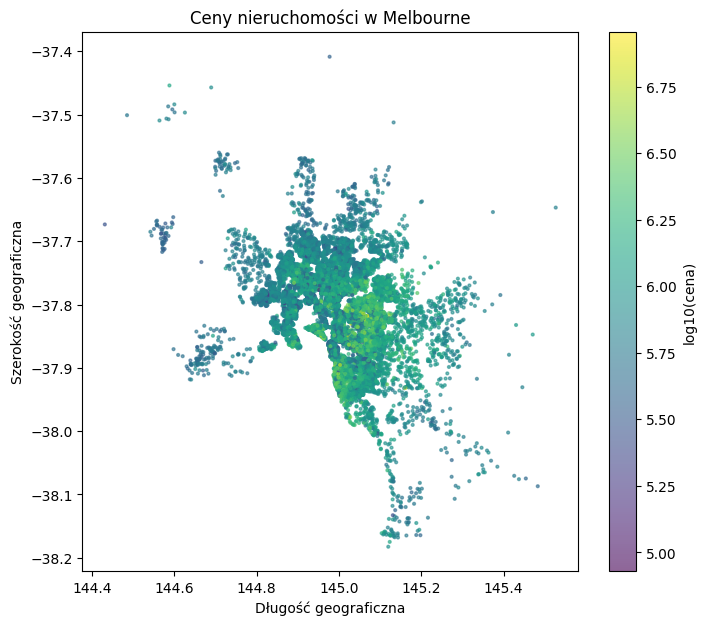

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(
    df["Longitude"], df["Latitude"],
    c=np.log10(df["Price"]), cmap="viridis", s=4, alpha=0.6,
)
fig.colorbar(sc, label="log10(cena)")
ax.set_title("Ceny nieruchomości w Melbourne")
ax.set_xlabel("Długość geograficzna")
ax.set_ylabel("Szerokość geograficzna")
plt.show()

### Od wykresów do hipotez: co potrafi model liniowy?

Model liniowy przewiduje sumę efektów: $\hat{y} = w_0 + w_1 x_1 + \ldots + w_d x_d$. Wynikają z tego ograniczenia, o których warto pamiętać, oglądając poniższe wykresy:

1. **Każda cecha działa liniowo.** Model zakłada, że każdy kolejny kilometr od centrum zmienia (logarytm) ceny o tyle samo - o wagę $w$. Na wykresie ceny względem odległości taki model zawsze rysuje prostą. Jeśli w rzeczywistości cena przez pierwsze kilometry prawie się nie zmienia, potem spada, a na obrzeżach znów się stabilizuje, jedna liczba $w$ tego nie opisze. Model dopasuje „uśrednioną” prostą, która w jednych miejscach zawyża, a w innych zaniża ceny. Modelowanie logarytmu ceny trochę pomaga, bo zamienia zmiany procentowe na stałe przyrosty, ale nie wyprostuje załamań krzywej.

2. **Efekty cech się nie łączą.** Model ma jedną wagę dla `Distance`, wspólną dla domów, szeregowców i mieszkań. Jeśli ceny domów spadają z odległością szybko, a ceny mieszkań prawie wcale, model tego nie odda.

Najpierw zobaczmy, jak cena zależy od typu nieruchomości i regionu. Kategorie są posortowane według mediany ceny, a oś ceny ma skalę logarytmiczną.

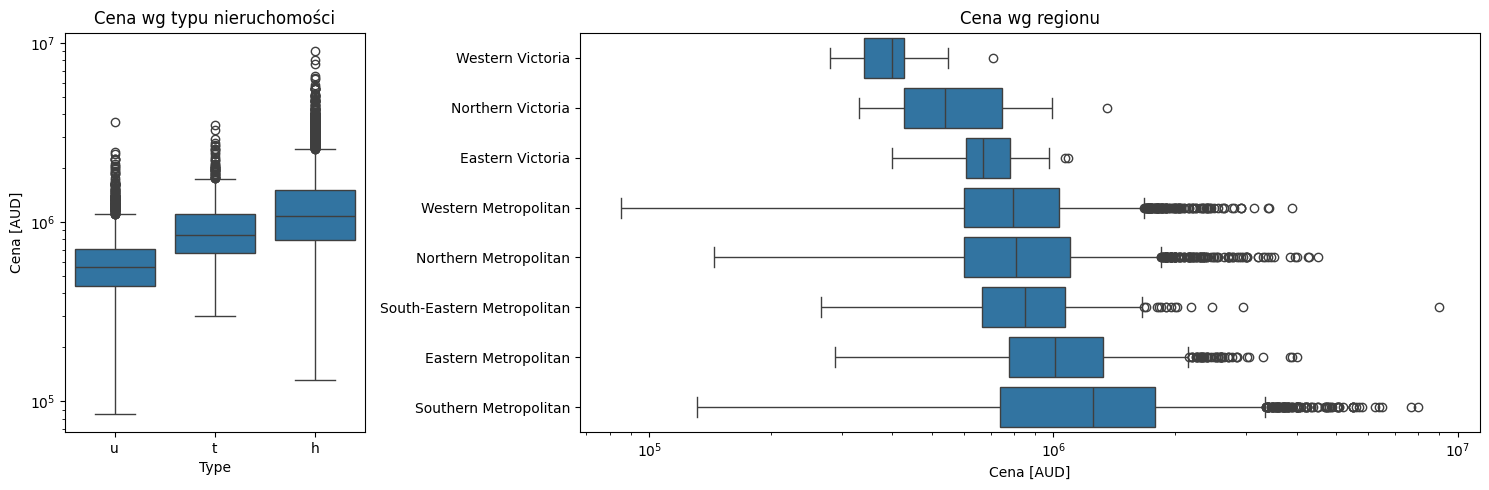

In [12]:
type_order = df.groupby("Type")["Price"].median().sort_values().index
region_order = df.groupby("Regionname")["Price"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 3]})
sns.boxplot(data=df, x="Type", y="Price", order=type_order, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Cena wg typu nieruchomości")
axes[0].set_ylabel("Cena [AUD]")
sns.boxplot(data=df, y="Regionname", x="Price", order=region_order, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Cena wg regionu")
axes[1].set_xlabel("Cena [AUD]")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

#### Cena a odległość od centrum

Sprawdźmy jeszcze, czy cena spada z odległością od centrum tak samo dla każdego typu nieruchomości. Poniższa komórka liczy medianę ceny w przedziałach co 2 km, osobno dla domów (`h`), szeregowców (`t`) i mieszkań (`u`). Pokazujemy tylko przedziały, w których jest co najmniej 20 sprzedaży: mediana z kilku transakcji to w dużej mierze przypadek. Na przykład w przedziale 26-28 km jest jeden szeregowiec - nowy, czteropokojowy, w nadmorskim Bonbeach, sprzedany za 1,83 mln AUD. Zanim zinterpretujesz punkt na wykresie, zawsze sprawdź, ile obserwacji za nim stoi.

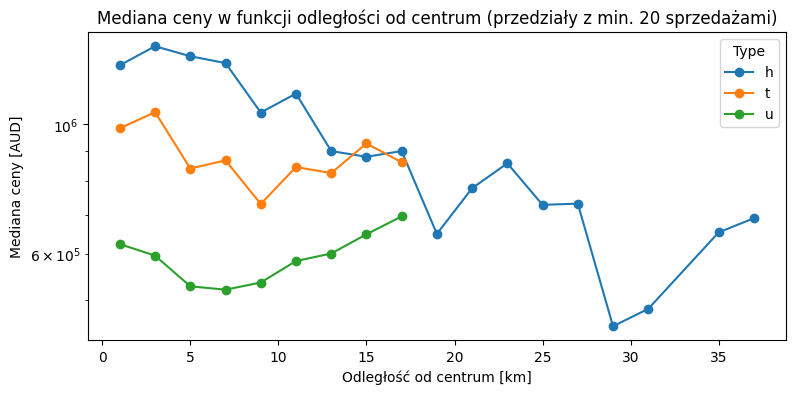

In [13]:
MIN_SALES = 20  # minimalna liczba sprzedaży w przedziale

distance_bins = pd.cut(df["Distance"], bins=np.arange(0, 52, 2), include_lowest=True)
stats = df.groupby([distance_bins, "Type"], observed=True)["Price"].agg(["median", "size"])
price_by_distance = stats["median"].where(stats["size"] >= MIN_SALES).unstack().dropna(how="all")

ax = price_by_distance.set_axis([iv.mid for iv in price_by_distance.index]).plot(
    marker="o", logy=True, figsize=(9, 4)
)
ax.set_title(f"Mediana ceny w funkcji odległości od centrum (przedziały z min. {MIN_SALES} sprzedażami)")
ax.set_xlabel("Odległość od centrum [km]")
ax.set_ylabel("Mediana ceny [AUD]")
plt.show()

**Co widać na wykresie?**
- **Domy (`h`):** ok. 1,3 mln AUD do ok. 8 km od centrum, dalej wyraźny spadek do ok. 0,7 mln AUD. Zależność nie jest prostą: najpierw płasko, potem spadek.
- **Mieszkania (`u`):** ok. 0,5-0,7 mln AUD niezależnie od odległości.
- **Szeregowce (`t`):** pomiędzy.

Wpływ odległości na cenę **zależy więc od typu nieruchomości**. Taką sytuację, w której wpływ jednej cechy zależy od wartości innej, nazywamy **interakcją** cech. Model liniowy ma jedną wagę `Distance` dla wszystkich typów, a kolumny `Type_*` mogą tylko przesunąć poziom ceny. Model dopasuje więc „uśrednione” nachylenie: dla domów niedoszacuje spadku ceny, a mieszkaniom przypisze spadek, którego nie ma. Pamiętaj o tym, oceniając wyniki modelu w części 3.

### Cechy kategoryczne i one-hot encoding

Model liniowy operuje na liczbach, więc kategorie trzeba zakodować. Naiwne podejście - zamiana `h`, `t`, `u` na 0, 1, 2 - wprowadza nieistniejący porządek („mieszkanie to dwa razy szeregowiec”). Dla cech **nominalnych** (bez naturalnego porządku) używamy **one-hot encoding**: każda kategoria dostaje osobną kolumnę binarną.

| Type | → | Type_h | Type_t | Type_u |
|---|---|---|---|---|
| h | | 1 | 0 | 0 |
| u | | 0 | 0 | 1 |

W scikit-learn robi to `OneHotEncoder`

#### Jak działa `OneHotEncoder`:

`OneHotEncoder` działa jak każdy transformator scikit-learn w dwóch krokach:
- `fit()` - **uczy się** listy kategorii na zbiorze treningowym i ją zapamiętuje,
- `transform()` - koduje dowolne dane zawsze do **tych samych** kolumn w tej samej kolejności. Kategorie nieznane obsługuje zgodnie z parametrem `handle_unknown`.

Dzięki temu zbiór treningowy, testowy i każdy nowy rekord w produkcji dostają identyczny zestaw kolumn. Ta zasada - *uczymy na treningu, stosujemy wszędzie* - dotyczy każdego przetwarzania danych i wróci w części 3.

#### Rzadkie kategorie i pułapka zmiennych "fikcyjnych"

Kolumna `Suburb` ma ponad 300 dzielnic. Większość z nich występuje w kilku–kilkudziesięciu wierszach - z tak małej liczby obserwacji model nie oszacuje wiarygodnej wagi. Parametr `min_frequency` w `OneHotEncoder` łączy kategorie rzadsze niż zadany próg w jedną kategorię „infrequent”. Zmniejsza to liczbę cech kosztem utraty części informacji o lokalizacji.

Kolumny one-hot jednej cechy zawsze sumują się do 1, czyli razem są równe kolumnie wyrazu wolnego - jedna z nich jest zbędna. To  *dummy variable trap*. Skutek: wagi kolumn one-hot nie są jednoznaczne. Można dodać tę samą liczbę do wszystkich wag `Type_*` i odjąć ją od wyrazu wolnego, a predykcje się nie zmienią. Sens mają więc tylko **różnice** wag w obrębie jednej cechy, np. `Type_h − Type_u`. Klasyczne rozwiązanie to `drop="first"`: jedna kategoria zostaje usunięta i staje się **kategorią odniesienia**, a wagi pozostałych mierzą różnicę względem niej. My go nie używamy, bo nieznana kategoria (np. nowa dzielnica) byłaby wtedy zakodowana samymi zerami, czyli tak samo jak kategoria odniesienia. Predykcje modelu i tak są poprawne, trzeba tylko pamiętać, żeby czytać różnice wag, a nie pojedyncze wagi.

W zadaniu 2 zobaczysz te efekty na naszych danych.

### Zadanie 2 (1 punkt) - one-hot encoding

**Cel:** zobaczyć, ile kolumn powstaje po one-hot encodingu cechy z wieloma kategoriami i jak ogranicza to parametr `min_frequency`.

Kolumna `Suburb` ma ponad 300 dzielnic.

1. Zakoduj `Suburb` zwykłym koderem `OneHotEncoder(sparse_output=False)` i zapisz liczbę utworzonych kolumn w `n_suburb_cols`.
2. Zakoduj `Suburb` jeszcze raz, tym razem z parametrem `min_frequency=0.01` (dzielnice występujące w mniej niż 1% wierszy trafią do jednej wspólnej kategorii). Liczbę kolumn zapisz w `n_suburb_cols_mf`.

**Pytanie:** ile kolumn powstało z `Suburb` w obu wariantach? Co zyskujemy, a co tracimy, łącząc rzadkie dzielnice w jedną kategorię?

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# TODO: kodowanie Suburb bez progu i z min_frequency=0.01
ohe = OneHotEncoder(sparse_output=False)
suburb_encoded = ohe.fit_transform(df[["Suburb"]])
n_suburb_cols = suburb_encoded.shape[1]

ohe_mf = OneHotEncoder(sparse_output=False, min_frequency=0.01)
suburb_encoded_mf = ohe_mf.fit_transform(df[["Suburb"]])
n_suburb_cols_mf = suburb_encoded_mf.shape[1]

print(f"Bez progu: {n_suburb_cols} kolumn")
print(f"Z min_frequency=0.01: {n_suburb_cols_mf} kolumn")
print("Kolumny po łączeniu rzadkich:", list(suburb_encoded_mf.columns))

Bez progu: 314 kolumn
Z min_frequency=0.01: 26 kolumn
Kolumny po łączeniu rzadkich: ['Suburb_Balwyn North', 'Suburb_Bentleigh', 'Suburb_Bentleigh East', 'Suburb_Brighton', 'Suburb_Brighton East', 'Suburb_Brunswick', 'Suburb_Carnegie', 'Suburb_Coburg', 'Suburb_Essendon', 'Suburb_Glen Iris', 'Suburb_Glenroy', 'Suburb_Hawthorn', 'Suburb_Kew', 'Suburb_Moonee Ponds', 'Suburb_Newport', 'Suburb_Northcote', 'Suburb_Pascoe Vale', 'Suburb_Port Melbourne', 'Suburb_Preston', 'Suburb_Reservoir', 'Suburb_Richmond', 'Suburb_South Yarra', 'Suburb_St Kilda', 'Suburb_Thornbury', 'Suburb_Yarraville', 'Suburb_infrequent_sklearn']


In [ ]:
assert n_suburb_cols == df["Suburb"].nunique()
assert n_suburb_cols_mf < n_suburb_cols
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


Odpowiedź:

- Bez progu około 300 kolumn, z min_frequency = 0.01 zostaje tylko kilkanaście kolumn.
- Zyskujemy znacznie mniej cech i wagi oszacowane na wystarczającej liczbie obserwacji, więc model mniej się przeucza. Tracimy informację o lokalizacji: wszystkie rzadkie dzielnice dostają tę samą wagę, choć ceny mogą się w nich bardzo różnić.


### Czyszczenie danych

Podczas EDA zauważysz kilka problemów typowych dla prawdziwych danych:

- **kolumny nieinformatywne lub problematyczne:** `Address` (unikalny identyfikator), `SellerG` (agencja - bardzo wiele kategorii, informacja wtórna), `Method` (sposób sprzedaży bywa znany dopiero w chwili transakcji - ryzyko *wycieku danych*), `Postcode` (to etykieta, nie liczba; duplikuje `Suburb`), `Bedroom2` (prawie kopia `Rooms`, z innego źródła),
- **wartości niemożliwe:** `BuildingArea == 0` oraz rok budowy wcześniejszy niż 1800 (Melbourne założono w 1835 roku),
- **obserwacje odstające (*outliers*):** pojedyncze budynki i działki o ogromnej powierzchni - regresja liniowa (funkcja kosztu MSE) jest na nie wrażliwa,
- **data jako tekst** w formacie `dd/mm/yyyy`.

Wartości niemożliwe zamieniamy na `NaN` zamiast usuwać całe wiersze - reszta informacji o nieruchomości jest wartościowa, a braki uzupełni później imputer.


#### Dlaczego funkcja i dlaczego osobno kolumny i wiersze?

Czyszczenie zapisujemy jako funkcję, a nie jako ciąg poleceń w komórkach, bo **dokładnie te same** operacje trzeba będzie wykonać na każdym nowym rekordzie, który model dostanie w produkcji. Funkcję można wywołać ponownie dla nowych danych albo włożyć jako krok do potoku (`Pipeline`) razem z modelem.


### Zadanie 3 (1 punkt) - czyszczenie danych

1. Uzupełnij funkcję `clean_features(data)`, która **nie modyfikuje** przekazanego `DataFrame` (zacznij od `.copy()`) i zwraca nowy, w którym:
   - usunięto kolumny z listy `columns_to_drop` (użyj `errors="ignore"`),
   - wartości `BuildingArea` równe 0 oraz wartości `YearBuilt` mniejsze niż 1800 zamieniono na `NaN`,
   - z kolumny `Date` (`pd.to_datetime(..., format="%d/%m/%Y")`) utworzono cechy `SaleYear` i `SaleMonth`,
   - utworzono cechę `HouseAge` = `SaleYear - YearBuilt`, a kolumny `Date` i `YearBuilt` usunięto.

   Funkcja musi działać także na danych **bez** kolumny `Price` - tak jak w produkcji.
2. Zastosuj funkcję: `df = clean_features(df)`.
3. Usuń z `df` wiersze, w których `BuildingArea > 1000` lub `Landsize > 20000`. **Uwaga:** wiersze z brakami w tych kolumnach mają zostać! Co można zaproponować zamiast usuwania takich wierszy z odstającymi wartoścami?

In [17]:
columns_to_drop = ["Address", "SellerG", "Method", "Postcode", "Bedroom2"]

df_raw = df.copy()


def clean_features(data):
    data = data.copy()
    data = data.drop(columns=columns_to_drop, errors="ignore")

    data["BuildingArea"] = data["BuildingArea"].mask(data["BuildingArea"] == 0)
    data["YearBuilt"] = data["YearBuilt"].mask(data["YearBuilt"] < 1800)

    dates = pd.to_datetime(data["Date"], format="%d/%m/%Y")
    data["SaleYear"] = dates.dt.year
    data["SaleMonth"] = dates.dt.month
    data["HouseAge"] = data["SaleYear"] - data["YearBuilt"]

    return data.drop(columns=["Date", "YearBuilt"])


# TODO: zastosuj clean_features i usuń wiersze odstające
df = clean_features(df)

outliers = (df["BuildingArea"] > 1000) | (df["Landsize"] > 20000)
df = df[~outliers]
print(f"Usunięto {outliers.sum()} wierszy odstających, zostało {len(df)}")

Usunięto 19 wierszy odstających, zostało 13561


In [18]:
assert "Date" in df_raw.columns, "clean_features() nie może modyfikować danych wejściowych"
assert "Price" not in clean_features(df_raw.drop(columns="Price").head()).columns
assert not set(columns_to_drop + ["Date", "YearBuilt"]) & set(df.columns)
assert {"SaleYear", "SaleMonth", "HouseAge"} <= set(df.columns)
_kept = df_raw.loc[~((df_raw["BuildingArea"] > 1000) | (df_raw["Landsize"] > 20000))]
assert df["BuildingArea"].min() > 0 and df["BuildingArea"].max() <= 1000
assert df["Landsize"].max() <= 20000
assert df.index.equals(_kept.index), "Usuń tylko wiersze z BuildingArea > 1000 lub Landsize > 20000 — wiersze z brakami mają zostać!"
assert df["BuildingArea"].isna().sum() == (_kept["BuildingArea"].isna() | (_kept["BuildingArea"] == 0)).sum()
assert df["HouseAge"].isna().sum() == (_kept["YearBuilt"].isna() | (_kept["YearBuilt"] < 1800)).sum(), "Wartości YearBuilt < 1800 zamień na NaN"
_dates = pd.to_datetime(_kept["Date"], format="%d/%m/%Y")
assert (df["SaleYear"] == _dates.dt.year).all() and (df["SaleMonth"] == _dates.dt.month).all()
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

Zamiast usuwać wiersze z odstającymi wartościami można przyciąć wartości do jakiejś granicy. Wtedy pozbędziemy się najbardziej ekstremalnych outlierów.

---

## Część 3. Regresja liniowa

Model regresji liniowej przewiduje wartość jako ważoną sumę cech:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \ldots + w_d x_d = w_0 + \mathbf{w}^T \mathbf{x}$$

Wagi dobieramy, minimalizując błąd średniokwadratowy (*mean squared error*, MSE) na zbiorze treningowym:

$$\min_{\mathbf{w}} \frac{1}{n} \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2$$

Model liniowy wymaga, żeby:
- nie było wartości brakujących - **imputacja**,
- cechy kategoryczne były zakodowane liczbowo - **one-hot encoding**,
- cechy miały podobną skalę - **standaryzacja** (konieczna przy regularyzacji, pomocna przy interpretacji wag).

### Wyciek danych (*data leakage*)

Wszystkie transformacje (mediany do imputacji, parametry skalowania, lista kategorii) **uczymy wyłącznie na zbiorze treningowym**, a zbiór testowy jedynie przekształcamy. W scikit-learn oznacza to `fit_transform()` na treningowym i `transform()` na testowym. Najwygodniej i najbezpieczniej jest zamknąć cały proces w obiekcie `Pipeline` - wtedy przy walidacji skrośnej transformacje będą poprawnie uczone osobno w każdym foldzie.

Przydatne klasy: [`ColumnTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html), [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [`SimpleImputer`](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

`OneHotEncoder` ma parametr `min_frequency` - kategorie rzadsze niż podany próg (np. 1% wierszy) zostaną połączone w jedną kategorię „infrequent”. Jest to szczególnie ważne dla kolumny `Suburb`, która ma ponad 300 unikalnych wartości.

### Jak zbudujemy przetwarzanie danych?

Zbierzmy decyzje z części 2 w jeden obiekt, który będzie częścią modelu:

| Problem | Rozwiązanie | Klasa | Uzasadnienie |
|---|---|---|---|
| braki w cechach numerycznych | mediana + wskaźnik braku | `SimpleImputer(strategy="median", add_indicator=True)` | mediana jest odporna na wartości odstające; wskaźnik mówi modelowi, że wartość była uzupełniona, a sam brak może nieść informację |
| różne skale cech | standaryzacja (średnia 0, odchylenie 1) | `StandardScaler` | wagi stają się porównywalne, a regularyzacja (część 4) karze wszystkie cechy jednakowo |
| braki w cechach kategorycznych | osobna kategoria `"Brak"` | `SimpleImputer(strategy="constant")` | brak informacji traktujemy jak informację, a nie zgadujemy kategorii |
| kategorie jako tekst | one-hot encoding z łączeniem rzadkich kategorii | `OneHotEncoder(min_frequency=0.01)` |  odporny na nowe kategorie (zadanie 2) |

`ColumnTransformer` kieruje kolumny numeryczne do jednego potoku, a kategoryczne do drugiego, i skleja wyniki. Cały obiekt uczymy (`fit`) **tylko na zbiorze treningowym**: mediany, średnie, odchylenia i listy kategorii pochodzą z treningu, a zbiór testowy jest jedynie przekształcany (`transform`). Gdybyśmy policzyli je na całych danych, informacja ze zbioru testowego „przeciekłaby” do modelu i wynik testowy byłby zawyżony.

### Zadanie 4 (2 punkty)

1. Wydziel wektor docelowy `y` (kolumna `Price`) oraz macierz cech `X` (pozostałe kolumny).
2. Podziel dane na zbiór treningowy i testowy w proporcji 80/20: `X_train, X_test, y_train, y_test`. Użyj `random_state=RANDOM_STATE`.
3. Utwórz listy `numerical_features` oraz `categorical_features` na podstawie typów kolumn w `X_train`.
4. Zbuduj `ColumnTransformer` w zmiennej `preprocessor`, z parametrem `verbose_feature_names_out=False`, składający się z dwóch potoków. **Zachowaj podane nazwy kroków** - będziemy się do nich odwoływać przy szukaniu hiperparametrów:
   - `"num"` - `Pipeline` z krokami `"imputer"` (`SimpleImputer` z medianą i `add_indicator=True`) oraz `"scaler"` (`StandardScaler`),
   - `"cat"` - `Pipeline` z krokami `"imputer"` (`SimpleImputer` ze strategią `"constant"` i wartością `"Brak"`) oraz `"onehot"` (`OneHotEncoder` z `handle_unknown="infrequent_if_exist"`, `min_frequency=0.01`, `sparse_output=False`).
5. Naucz `preprocessor` na zbiorze treningowym i przekształć oba zbiory: `X_train_prep`, `X_test_prep`.
6. Odpowiedz: które kolumny dostały wskaźnik braku (nazwy zaczynające się od `missingindicator_`)? Dlaczego akurat te, a nie wszystkie kolumny numeryczne?

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# TODO: X, y i podział na zbiory
y = df["Price"]
X = df.drop(columns="Price")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# TODO: listy cech
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

# TODO: preprocessor
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Brak")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False
    )),
])
preprocessor = ColumnTransformer(
    [
        ("num", num_pipeline, numerical_features),
        ("cat", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# TODO: transformacja zbiorów
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)
print([c for c in X_train_prep.columns if c.startswith("missingindicator_")])

(10848, 71) (2713, 71)
['missingindicator_Car', 'missingindicator_BuildingArea', 'missingindicator_HouseAge']


In [20]:
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert abs(len(X_test) / len(X) - 0.2) < 0.01
assert "Price" not in X_train.columns
assert set(categorical_features) == {"Suburb", "Type", "CouncilArea", "Regionname"}
assert isinstance(X_train_prep, pd.DataFrame)
assert X_train_prep.shape[1] == X_test_prep.shape[1]
assert X_train_prep.isna().sum().sum() == 0 and X_test_prep.isna().sum().sum() == 0
assert np.allclose(X_train_prep[numerical_features].mean(), 0, atol=1e-6)
assert any(col.startswith("missingindicator_") for col in X_train_prep.columns)
assert X_train_prep.shape[1] < 100, "Za dużo cech — czy ustawiłeś min_frequency?"
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

Wskaźnik powstaje tylko dla kolumn, w których podczas `fit` wystąpił jakiś brak (domyślnie `features="missing-only"`). Dla pozostałych kolumn byłaby to kolumna samych zer, która nic nie wnosi.

---

### Model, transformacja zmiennej docelowej i metryki

Model będzie przewidywał **logarytm** ceny, ale metryki chcemy raportować w dolarach. Wygodnie rozwiązuje to [`TransformedTargetRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html): przy `fit()` logarytmuje `y` (`np.log1p`), a przy `predict()` automatycznie stosuje transformację odwrotną (`np.expm1`).

Funkcja `make_model()` poniżej buduje pełny potok: przetwarzanie + model. Dzięki `clone()` każdy model dostaje **świeży, nienauczony** preprocessor.

Metryki regresji, których użyjemy:
- **MAE** (*mean absolute error*) - średni błąd bezwzględny, w dolarach; łatwy do wytłumaczenia klientowi,
- **RMSE** (*root mean squared error*) - mocniej karze duże pomyłki, także w dolarach,
- **MdAPE** (*median absolute percentage error*) - mediana błędu procentowego $|y - \hat{y}| / y$; mówi, o ile procent myli się typowa wycena, niezależnie od tego, czy nieruchomość jest tania, czy droga. Pozwala ocenić, czy błąd w dolarach jest duży w stosunku do ceny.

<!-- **A co z $R^2$?** W wielu materiałach spotkasz też współczynnik determinacji (`sklearn.metrics.r2_score`):

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

Mówi, o ile model jest lepszy od przewidywania średniej: 1 to ideał, 0 to poziom średniej, a na zbiorze testowym może być nawet ujemny. Jest popularny, ale w tym laboratorium go nie używamy, bo ma istotne ograniczenia:
- **jest względny** — zależy od rozrzutu cen w ocenianym zbiorze, więc ten sam błąd w dolarach daje różne $R^2$ na różnych zbiorach; nie da się porównywać wyników między zbiorami danych,
- **nie ma jednostki** — nie mówi, o ile dolarów model się myli,
- **liczy kwadraty błędów**, więc o wyniku decydują najdroższe domy z największymi pomyłkami,
- **na zbiorze treningowym nie spada przy dodawaniu cech**, nawet zupełnie losowych. -->
<!-- 
Nie jest też metryką w sensie matematycznym: to nie odległość między wartościami prawdziwymi a przewidywanymi (może być ujemny i nie jest symetryczny). Dlatego dokumentacja scikit-learn nazywa go *score*, a nie metryką. -->



In [22]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor


def make_model(regressor):
    return Pipeline([
        ("prep", clone(preprocessor)),
        ("model", TransformedTargetRegressor(
            regressor=regressor, func=np.log1p, inverse_func=np.expm1
        )),
    ])

### Jak czytać wyniki modelu?
Zawsze warto porównać się z **modelem bazowym** (*baseline*), np. `DummyRegressor`, który dla każdego domu przewiduje medianę ceny. Model, który go nie pokonuje, jest bezużyteczny.

**Baseline.** Sama liczba typu „MAE = 250 tys. AUD” zazwyczaj niewiele mówi, dopóki nie wiemy, jaki błąd daje najprostsze możliwe podejście. `DummyRegressor` przewiduje dla każdego domu medianę ceny ze zbioru treningowego. Każdy sensowny model musi go wyraźnie pokonać.

**Trening kontra test.** Porównanie błędów na obu zbiorach to podstawowa diagnoza modelu:
- błąd treningowy **dużo mniejszy** niż testowy → model nauczył się szczegółów zbioru treningowego, które się nie powtarzają - jest **przeuczony** (*overfitting*, wysoka wariancja),
- oba błędy **podobne i wysokie** → model jest za prosty, żeby uchwycić zależności w danych - jest **niedouczony** (*underfitting*, wysokie obciążenie),
- oba błędy podobne i niskie → dobrze.

Ta diagnoza decyduje, co robić dalej: na przeuczenie pomaga regularyzacja i więcej danych, na niedouczenie - bardziej pojemny model.

### Zadanie 5 (1 punkt)

1. Uzupełnij funkcję `evaluate_model()`:
   - oblicz predykcje dla zbioru treningowego i testowego,
   - oblicz MAE i RMSE dla obu zbiorów (`mean_absolute_error`, `root_mean_squared_error`),
   - oblicz medianę błędu procentowego na zbiorze testowym: `test_MdAPE` = mediana z $|y - \hat{y}| / y$, razy 100 (wynik w procentach; przyda się `np.median` i `np.abs`),
   - wypisz metryki (MAE i RMSE zaokrąglone do pełnych dolarów, MdAPE do 1 miejsca po przecinku),
   - zwróć słownik z kluczami `"model"`, `"train_MAE"`, `"test_MAE"`, `"train_RMSE"`, `"test_RMSE"`, `"test_MdAPE"`.
2. Utwórz i naucz na `X_train`, `y_train` dwa modele: `baseline = make_model(DummyRegressor(strategy="median"))` oraz `lin_reg = make_model(LinearRegression())`.
3. Oceń oba modele i dodaj zwrócone słowniki do listy `results` - będziemy ją rozbudowywać do końca laboratorium.
4. Odpowiedz: czy model jest przeuczony (*overfitting*) albo niedouczony (*underfitting*)? Po czym to poznajesz? Czy błąd, jaki popełnia model, byłby akceptowalny przy realnej wycenie nieruchomości?

In [23]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error


def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    metrics = {
        "model": name,
        "train_MAE": mean_absolute_error(y_train, y_train_pred),
        "test_MAE": mean_absolute_error(y_test, y_test_pred),
        "train_RMSE": root_mean_squared_error(y_train, y_train_pred),
        "test_RMSE": root_mean_squared_error(y_test, y_test_pred),
        "test_MdAPE": np.median(np.abs(y_test - y_test_pred) / y_test) * 100,
    }

    print(f"--- {name} ---")
    print(f"MAE:   train {metrics['train_MAE']:,.0f}  test {metrics['test_MAE']:,.0f}")
    print(f"RMSE:  train {metrics['train_RMSE']:,.0f}  test {metrics['test_RMSE']:,.0f}")
    print(f"MdAPE: test {metrics['test_MdAPE']:.1f}%")
    return metrics


results = []

# TODO: baseline i regresja liniowa
baseline = make_model(DummyRegressor(strategy="median"))
baseline.fit(X_train, y_train)

lin_reg = make_model(LinearRegression())
lin_reg.fit(X_train, y_train)

results.append(evaluate_model(baseline, X_train, y_train, X_test, y_test, "Baseline (mediana)"))
results.append(evaluate_model(lin_reg, X_train, y_train, X_test, y_test, "Regresja liniowa"))

--- Baseline (mediana) ---
MAE:   train 441,169  test 433,955
RMSE:  train 664,091  test 651,584
MdAPE: test 33.9%
--- Regresja liniowa ---
MAE:   train 214,373  test 217,131
RMSE:  train 357,686  test 371,654
MdAPE: test 15.8%


In [24]:
assert len(results) == 2
assert set(results[1]) == {"model", "train_MAE", "test_MAE", "train_RMSE", "test_RMSE", "test_MdAPE"}
assert 0 < results[1]["test_MdAPE"] < 50, "MdAPE podaj w procentach"
assert results[1]["test_MAE"] < 0.7 * results[0]["test_MAE"], "Regresja liniowa powinna wyraźnie pokonać baseline"
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

Model nie jest przeuczony: MAE i RMSE na zbiorze treningowym i testowym są bardzo zbliżone. Wyraźnie pokonuje baseline (MAE spada z 434 tys. do 217 tys AUD), ale błędy na obu zbiorach są nadal duże. Wskazuje to raczej na niedouczenie

Przy realnej wycenie taki błąd byłby nieakceptowalny. Typowa wycena myli się o ok. 15% (MdAPE), co przy domu za 1 mln AUD oznacza ok. 150 tys. AUD.

---

### Rezydua i wagi modelu przewidującego logarytm ceny

**Regresja do średniej.** Na wykresie „cena prawdziwa vs przewidywana” zwykle widać, że model zaniża ceny najdroższych nieruchomości i zawyża ceny najtańszych. Model „ostrożnie” przewiduje wartości bliżej środka rozkładu, bo skrajne ceny zależą też od rzeczy, których nie ma w danych (stan techniczny, widok, ogród).

**Jak czytać wagi.**
- Cechy numeryczne są ustandaryzowane. Waga $w$ mówi, co się dzieje z ceną, gdy cecha rośnie o **jedno odchylenie standardowe**, a pozostałe cechy się nie zmieniają: cena jest wtedy **mnożona przez $e^{w}$**.
- Dla małych wag $e^{w} \approx 1 + w$, więc waga 0.05 to ok. +5% ceny, a waga −0.10 to ok. −10%.
- Dla kolumn one-hot patrzymy na **różnicę wag** dwóch kategorii tej samej cechy, a nie na pojedynczą wagę (patrz *dummy variable trap* w opisie przed zadaniem 2). Przykład: $e^{w_u - w_h}$ mówi, ile razy mieszkanie jest droższe lub tańsze od domu o tych samych pozostałych cechach.

**Uwaga na cechy skorelowane.** Cechy takie jak `Rooms` i `BuildingArea` zwykle rosną razem, więc „zmiana jednej przy stałej drugiej” rzadko zdarza się w rzeczywistości. Model może wtedy dowolnie podzielić wspólny efekt między te cechy, czasem nawet nadając jednej z nich zaskakujący znak, np. ujemną wagę dla liczby pokoi. Wag takich cech nie należy czytać zbyt dosłownie.

### Zadanie 6 (1 punkt)

Same metryki to za mało - warto zobaczyć, **gdzie** model się myli i **czego** się nauczył.

1. Oblicz rezydua $y - \hat{y}$ regresji liniowej na zbiorze testowym (w dolarach) i zapisz w `residuals`. Narysuj ich rozkład funkcją `plot_distribution()`.
2. Narysuj wykres punktowy: cena prawdziwa (oś X) vs przewidywana (oś Y), na zbiorze testowym. Dodaj przekątną $y = x$. Rozważ skalę logarytmiczną obu osi.
3. Pobierz wagi modelu (`lin_reg.named_steps["model"].regressor_.coef_`) wraz z nazwami cech (`lin_reg.named_steps["prep"].get_feature_names_out()`) jako `pd.Series` w zmiennej `coefs`. Narysuj 15 cech o największej **wartości bezwzględnej** wagi na poziomym wykresie słupkowym.
4. Odpowiedz:
   - Dla jakich nieruchomości model myli się najbardziej? Czy Twoje wykresy potwierdzają opis z komórki powyżej?
   - Wybierz z wektora `coefs` jedną cechę numeryczną i zinterpretuj jej wagę jako procentową zmianę ceny. Następnie porównaj wagi `Type_h` i `Type_u`: o ile procent mieszkanie jest tańsze od domu o tych samych pozostałych cechach?

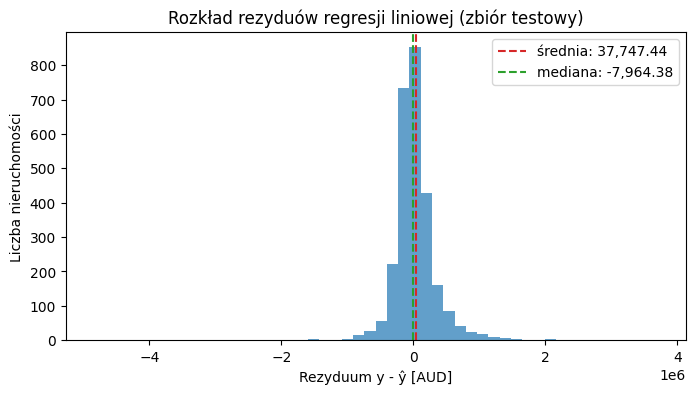

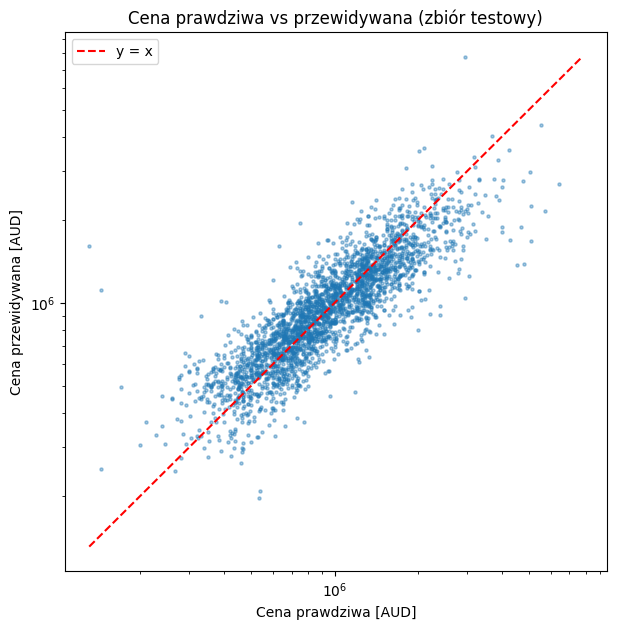

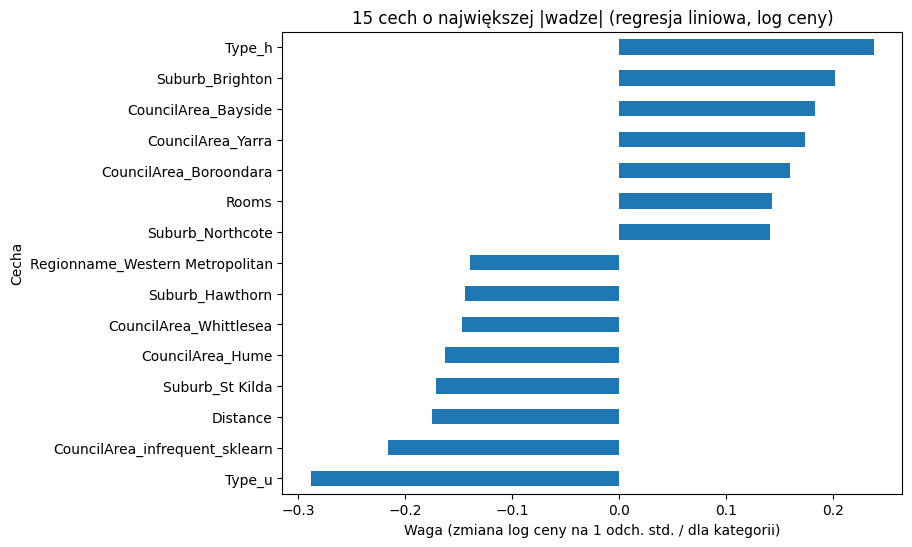

BuildingArea: waga 0.057 -> +5.9% ceny
Type_u - Type_h = -0.527 -> mieszkanie -40.9% względem domu


In [ ]:
# TODO: rezydua
y_test_pred = lin_reg.predict(X_test)
residuals = y_test - y_test_pred
plot_distribution(residuals, "Rozkład rezyduów regresji liniowej (zbiór testowy)", "Rezyduum y - ŷ [AUD]")

# TODO: prawdziwe vs przewidywane scatterplot
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_test_pred, s=5, alpha=0.4)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, color="red", linestyle="--", label="y = x")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Cena prawdziwa vs przewidywana (zbiór testowy)")
ax.set_xlabel("Cena prawdziwa [AUD]")
ax.set_ylabel("Cena przewidywana [AUD]")
ax.legend()
plt.show()

# TODO: wagi modelu jako hbarplot
coefs = pd.Series(
    lin_reg.named_steps["model"].regressor_.coef_,
    index=lin_reg.named_steps["prep"].get_feature_names_out(),
)
top15 = coefs.loc[coefs.abs().sort_values(ascending=False).index[:15]]

ax = top15.sort_values().plot.barh(figsize=(8, 6))
ax.set_title("15 cech o największej |wadze| (regresja liniowa, log ceny)")
ax.set_xlabel("Waga (zmiana log ceny na 1 odch. std. / dla kategorii)")
ax.set_ylabel("Cecha")
plt.show()

print(f"BuildingArea: waga {coefs['BuildingArea']:.3f} -> {np.expm1(coefs['BuildingArea']) * 100:+.1f}% ceny")
diff_uh = coefs["Type_u"] - coefs["Type_h"]
print(f"Type_u - Type_h = {diff_uh:.3f} -> mieszkanie {np.expm1(diff_uh) * 100:+.1f}% względem domu")

In [26]:
assert len(residuals) == len(y_test)
assert isinstance(coefs, pd.Series) and len(coefs) == X_train_prep.shape[1]
assert "Rooms" in coefs.index
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

- Model myli się najbardziej dla najdroższych nieruchomości (zaniża ich ceny) i najtańszych (zawyża). Na wykresie punkty na krańcach odchylają się od przekątnej w stronę środka, a rozkład rezyduów ma długi prawy ogon. To potwierdza efekt regresji do średniej.

- Waga `BuildingArea` = 0,057: wzrost powierzchni budynku o jedno odchylenie standardowe, przy pozostałych cechach bez zmian, podnosi cenę o ok. 5,9% ($e^{0.057} - 1 \approx 0.059$). Efekt jest mniejszy, niż można by się spodziewać, bo część wpływu powierzchni przejmuje skorelowana z nią cecha `Rooms`.

- Różnica wag `Type_u` − `Type_h` = −0,527, więc mieszkanie jest o ok. 41% tańsze od domu o tych samych pozostałych cechach ($e^{-0.527} \approx 0.59$).

---

## Część 4. Regularyzacja

Gdy cech jest dużo albo są ze sobą skorelowane, wagi regresji liniowej mogą przyjmować duże wartości i model zaczyna dopasowywać się do szumu czyli dochodzi do przeuczenia. **Regularyzacja** dodaje do funkcji kosztu karę za wielkość wag:

- **ridge (L2):** $\quad \text{MSE} + \alpha \sum_j w_j^2 \quad$ - zmniejsza wszystkie wagi, ale rzadko do zera,
- **LASSO (L1):** $\quad \text{MSE} + \alpha \sum_j |w_j| \quad$ - potrafi wyzerować część wag, więc dokonuje **selekcji cech**,
- **ElasticNet:** kombinacja obu, z proporcją sterowaną przez `l1_ratio`.

Hiperparametr $\alpha$ kontroluje siłę regularyzacji: $\alpha = 0$ to zwykła regresja liniowa, bardzo duże $\alpha$ prowadzi do modelu prawie stałego (niedouczenie). Kara zależy od wielkości wag, a te od skali cech - dlatego **standaryzacja jest przy regularyzacji obowiązkowa**. Wyraz wolny $w_0$ nie jest regularyzowany.


#### Kiedy regularyzacja pomaga, a kiedy nie?

Regularyzacja zmniejsza **wariancję** modelu kosztem niewielkiego wzrostu obciążenia. Pomaga więc przede wszystkim modelom przeuczonym: gdy cech jest dużo w stosunku do liczby próbek, gdy cechy są silnie skorelowane albo gdy dużo jest rzadkich kolumn po one-hot encoding. Jeśli model jest  niedouczony (zadanie 5), zysk z regularyzacji będzie niewielki.
#### Czym różnią się kary L1 i L2?

- **Ridge (L2)** karze kwadraty wag, więc najmocniej zmniejsza duże wagi. Wagi maleją płynnie wraz z $\alpha$, ale praktycznie nigdy nie stają się dokładnie zerem. Gdy kilka cech jest skorelowanych, Ridge rozkłada wagę między nie.
- **LASSO (L1)** karze wartości bezwzględne wag. Ma to taką właściwość, że część wag staje się **dokładnie zerem** - LASSO samo wybiera cechy. 
- **ElasticNet** łączy obie kary: `l1_ratio` mówi, jaka część kary to L1. Składnik L2 sprawia, że ze skorelowanej grupy ElasticNet zachowuje kilka cech naraz (*efekt grupowania*), a składnik L1 wciąż zeruje cechy nieprzydatne. Przy tym samym $\alpha$ kara L1 jest w ElasticNet słabsza niż w LASSO, więc zeruje mniej wag.

W zadaniu 7 sprawdzisz, czy w naszym przypadku regularyzacja poprawia wynik w porównaniu ze zwykłą regresją liniową z zadania 5.

### Zadanie 7 (1 punkt) — regularyzacja a zwykła regresja liniowa

1. Naucz trzy modele z regularyzacją: `ridge = make_model(Ridge(alpha=1.0))`, `lasso = make_model(Lasso(alpha=1e-3, max_iter=10_000))` oraz `enet = make_model(ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=10_000))`. Oceń je funkcją `evaluate_model()` i dopisz wyniki do `results`.
2. Zestaw w tabeli `reg_comparison` (`pd.DataFrame`) wyniki zwykłej regresji liniowej z zadania 5 i trzech nowych modeli: kolumny `model`, `test_MAE`, `test_RMSE`.
3. Policz, ile wag jest niezerowych w LASSO i w ElasticNet (`n_nonzero_lasso`, `n_nonzero_enet`), i porównaj z liczbą wszystkich cech.
4. Odpowiedz: czy regularyzacja poprawiła wynik względem zwykłej regresji liniowej? Dlaczego na tych danych tak jest (przypomnij sobie diagnozę z zadania 5 oraz liczbę próbek i cech)? Co mimo to daje nam LASSO?

In [27]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge

# TODO 1: ridge, LASSO i ElasticNet
ridge = make_model(Ridge(alpha=1.0)).fit(X_train, y_train)
lasso = make_model(Lasso(alpha=1e-3, max_iter=10_000)).fit(X_train, y_train)
enet = make_model(ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=10_000)).fit(X_train, y_train)

results.append(evaluate_model(ridge, X_train, y_train, X_test, y_test, "Ridge"))
results.append(evaluate_model(lasso, X_train, y_train, X_test, y_test, "LASSO"))
results.append(evaluate_model(enet, X_train, y_train, X_test, y_test, "ElasticNet"))

# TODO 2: tabela porównawcza
reg_comparison = pd.DataFrame(results[1:5])[["model", "test_MAE", "test_RMSE"]]
display(reg_comparison.round(0))

# TODO 3: liczba niezerowych wag
n_nonzero_lasso = np.count_nonzero(lasso.named_steps["model"].regressor_.coef_)
n_nonzero_enet = np.count_nonzero(enet.named_steps["model"].regressor_.coef_)
print(f"Niezerowe wagi: LASSO {n_nonzero_lasso}, ElasticNet {n_nonzero_enet}, wszystkich cech {X_train_prep.shape[1]}")

--- Ridge ---
MAE:   train 214,377  test 217,128
RMSE:  train 357,711  test 371,618
MdAPE: test 15.8%
--- LASSO ---
MAE:   train 218,160  test 220,442
RMSE:  train 362,868  test 372,462
MdAPE: test 16.3%
--- ElasticNet ---
MAE:   train 215,928  test 218,533
RMSE:  train 360,063  test 371,378
MdAPE: test 15.9%


,model,test_MAE,test_RMSE
0,Regresja liniowa,217131.0,371654.0
1,Ridge,217128.0,371618.0
2,LASSO,220442.0,372462.0
3,ElasticNet,218533.0,371378.0


Niezerowe wagi: LASSO 44, ElasticNet 60, wszystkich cech 71


In [28]:
assert len(results) == 5
assert isinstance(reg_comparison, pd.DataFrame) and len(reg_comparison) == 4
assert {"model", "test_MAE", "test_RMSE"} <= set(reg_comparison.columns)
assert 0 < n_nonzero_lasso < X_train_prep.shape[1]
assert 0 < n_nonzero_enet <= X_train_prep.shape[1]
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

Regularyzacja nie poprawiła wyniku: Ridge ma praktycznie to samo MAE co zwykła regresja liniowa (ok. 217,1 tys. AUD), a LASSO i ElasticNet są nawet nieco gorsze (ok. 220,4 i 218,5 tys. AUD). Wynika to z diagnozy z zadania 5: model nie jest przeuczony, tylko niedouczony, a przy ok. 11 tys. próbek treningowych i niecałych 100 cechach wagi są szacowane stabilnie. LASSO mimo to wyzerowało część wag (zostało 44 z 71 cech), czyli samo dokonało selekcji cech, więc model jest prostszy i łatwiejszy w interpretacji.

---

## Część 5. Szukanie hiperparametrów

**Parametrów** (wagi) model uczy się sam z danych, natomiast **hiperparametry** (np. $\alpha$, `min_frequency`) ustalamy, zanim zacznie się uczenie. Hiperparametrów **nie można** dobierać na zbiorze testowym - wtedy wynik testowy przestaje być uczciwą oceną na nowych danych.

Rozwiązanie to **walidacja skrośna** (*k-fold cross-validation*): zbiór treningowy dzielimy na $k$ części, uczymy model na $k-1$ częściach i oceniamy na pozostałej, a wynik uśredniamy. Dla każdej kombinacji hiperparametrów dostajemy stabilną ocenę jakości bez zbioru testowego.

Strategie przeszukiwania:
- [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) - sprawdza wszystkie kombinacje z siatki. Dokładne, ale koszt rośnie wykładniczo z liczbą hiperparametrów,
- [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) - losuje zadaną liczbę kombinacji z rozkładów. Zwykle znacznie wydajniejsze przy wielu hiperparametrach


Ponieważ mamy jeden `Pipeline`, możemy szukać **jednocześnie** hiperparametry modelu i przetwarzania danych. Nazwy budujemy z nazw kroków połączonych podwójnym podkreśleniem, np.:
- `model__regressor__alpha` - $\alpha$ regresora wewnątrz `TransformedTargetRegressor`,
- `prep__cat__onehot__min_frequency` - próg rzadkich kategorii w one-hot encoderze.

Listę wszystkich dostępnych nazw zwraca `model.get_params().keys()`.

Scikit-learn zawsze **maksymalizuje** wynik, dlatego metryki błędu podajemy ze znakiem minus, np. `scoring="neg_mean_absolute_error"`.

In [29]:
# podgląd nazw hiperparametrów dostępnych w potoku
[name for name in make_model(Ridge()).get_params() if "alpha" in name or "min_frequency" in name]

['prep__cat__onehot__min_frequency', 'model__regressor__alpha']

### Jak czytać krzywą walidacji i dlaczego losujemy hiperparametry?

**Krzywa walidacji** pokazuje w funkcji jednego hiperparametru **dwa** błędy: treningowy (na częściach (foldach), na których model się uczył) i walidacyjny (na części odłożonej w walidacji skrośnej). Dopiero ich zestawienie pozwala postawić diagnozę:
- **przeuczenie** - błąd treningowy niski, walidacyjny wyraźnie wyższy: duża luka między liniami,
- **niedouczenie** - oba błędy wysokie i blisko siebie,
- **dobry model** - oba błędy niskie i blisko siebie.

Dla regularyzacji typowy kształt to: po lewej (małe $\alpha$) kara jest pomijalna i model to praktycznie zwykła regresja liniowa; im większe $\alpha$, tym bardziej wagi są ściskane do zera, błąd treningowy rośnie, a luka między liniami maleje. Jeśli model po lewej jest przeuczony, błąd walidacyjny najpierw spada, a optimum leży tam, gdzie luka zniknęła, zanim oba błędy zaczną rosnąć.

Zaznaczamy też **odchylenie standardowe** wyniku między podziałami walidacji skrośnej. Różnice między wartościami $\alpha$ mniejsze od tego odchylenia to w praktyce szum.

**Siatka kontra losowanie.** `GridSearchCV` sprawdza każdą kombinację, więc koszt rośnie wykładniczo z liczbą hiperparametrów: 13 wartości $\alpha$ × 10 wartości `l1_ratio` × 5 podziałów = 650 uczeń modelu. `RandomizedSearchCV` losuje zadaną liczbę kombinacji, więc to my ustalamy budżet. Gdy tylko jeden z hiperparametrów naprawdę ma znaczenie, losowanie sprawdza wiele **różnych** jego wartości, a siatka tylko kilka.

**Skala logarytmiczna.** $\alpha$ działa w skali rzędów wielkości: zmiana z $10^{-4}$ na $10^{-3}$ jest równie istotna jak z $10^{-2}$ na $10^{-1}$. Losując $\alpha$ jednostajnie z przedziału $[10^{-5}, 10^{-1}]$, ok. 90% losowań trafiłoby do $[0.01, 0.1]$. Rozkład log-jednostajny (`loguniform`) daje tyle samo losowań w każdym przedziale. `l1_ratio` jest proporcją z przedziału $[0, 1]$, więc losujemy je zwyczajnie, jednostajnie.

### Zadanie 8 (2 punkty)

1. Użyj `GridSearchCV` w zmiennej `ridge_search` do tuningowania modelu `make_model(Ridge())`:
   - `model__regressor__alpha`: 17 wartości z `np.logspace(-3, 5, 17)`,
   - `prep__cat__onehot__min_frequency`: `[0.005, 0.01, 0.05]`,
   - walidacja: `KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`, metryka: `"neg_mean_absolute_error"`, `n_jobs=-1`,
   - `return_train_score=True` — żeby `cv_results_` zawierało też błąd treningowy.
2. Wypisz najlepsze hiperparametry i najlepsze MAE z walidacji (jako liczbę dodatnią).
3. **Krzywa walidacji:** z `ridge_search.cv_results_` wybierz wyniki dla najlepszego `min_frequency` i narysuj na jednym wykresie dwie linie w funkcji $\alpha$ (skala logarytmiczna na osi X): średnie MAE treningowe (`mean_train_score`) i średnie MAE walidacyjne (`mean_test_score`). Pamiętaj o zmianie znaku. Dla linii walidacyjnej dodaj obszar ± odchylenie standardowe (`plt.fill_between`).
4. Oceń `ridge_search.best_estimator_` na zbiorze testowym i dopisz wynik do `results`.
5. **ElasticNet ma dwa hiperparametry**, więc użyj `RandomizedSearchCV` w zmiennej `enet_search` do strojenia `make_model(ElasticNet(max_iter=10_000))`:
   - `model__regressor__alpha`: rozkład `loguniform(1e-5, 1e-1)`,
   - `model__regressor__l1_ratio`: rozkład `uniform(0.05, 0.9)` (czyli przedział $[0.05, 0.95]$),
   - `n_iter=20`, ta sama walidacja i metryka co dla ridge, `random_state=RANDOM_STATE`, `n_jobs=-1`.
6. Zmierz czas obu przeszukiwań (`time.perf_counter()`) i zapisz w `ridge_time` oraz `enet_time` (w sekundach). Wypisz najlepsze hiperparametry ElasticNet, oceń najlepszy model na zbiorze testowym i dopisz wynik do `results`.
7. Odpowiedz:
   - Jak daleko od siebie są linie błędu treningowego i walidacyjnego? Gdzie na wykresie widać niedouczenie, a gdzie byłoby widać przeuczenie, gdyby występowało? Co z tego wynika dla sensu regularyzacji na tych danych?
   - Porównaj zmierzone czasy `ridge_time` i `enet_time` z liczbą sprawdzonych kombinacji. Ile trwałoby przeszukanie pełnej siatki 13 × 10 dla ElasticNet?
   - Jakie `l1_ratio` wybrało przeszukiwanie - czy model jest bliżej ridge, czy LASSO? Sprawdź w `enet_search.cv_results_`, czy wyniki dla różnych `l1_ratio` istotnie się różnią.

Ridge - najlepsze hiperparametry: {'model__regressor__alpha': np.float64(3.1622776601683795), 'prep__cat__onehot__min_frequency': 0.005}
Ridge - najlepsze MAE (CV): 210,370


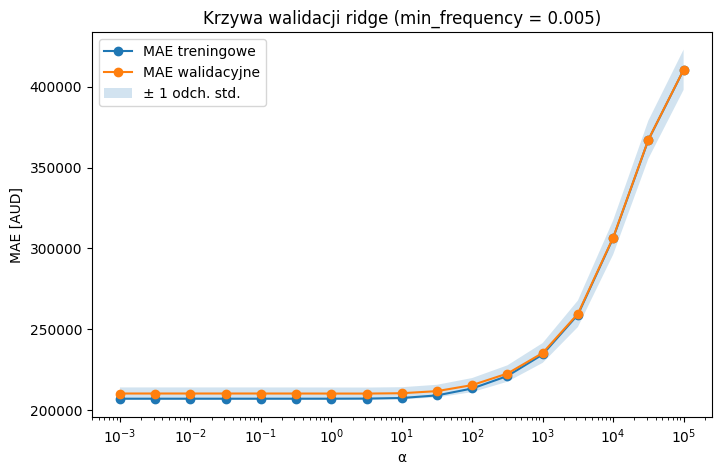

--- Ridge (GridSearchCV) ---
MAE:   train 207,582  test 212,755
RMSE:  train 348,417  test 362,400
MdAPE: test 15.7%
ElasticNet - najlepsze hiperparametry: {'model__regressor__alpha': np.float64(4.207988669606632e-05), 'model__regressor__l1_ratio': np.float64(0.1903950683025824)}
ElasticNet - najlepsze MAE (CV): 216,165
--- ElasticNet (RandomizedSearchCV) ---
MAE:   train 214,376  test 217,129
RMSE:  train 357,704  test 371,610
MdAPE: test 15.8%

Ridge: 7.0 s na 51 kombinacji (0.14 s/komb.)
ElasticNet: 32.4 s na 20 kombinacji (1.62 s/komb.)
Szacowany czas pełnej siatki 13 x 10 dla ElasticNet: 211 s


,param_model__regressor__alpha,param_model__regressor__l1_ratio,MAE,std_test_score
2,0.0000,0.1904,216165.1255,3883.0109
7,0.0001,0.2151,216165.6524,3886.7138
5,0.0000,0.9229,216166.9796,3881.6346
3,0.0000,0.8296,216167.9845,3884.6094
16,0.0000,0.9040,216168.8615,3886.4314
18,0.0002,0.1379,216171.6830,3907.1357
13,0.0001,0.5128,216176.7098,3903.8246
11,0.0001,0.3797,216195.5313,3934.1670
8,0.0002,0.5223,216225.0298,3960.7754
9,0.0005,0.3121,216371.2183,4075.0111


In [32]:
import time

from scipy.stats import loguniform, uniform
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# TODO: GridSearchCV dla ridge (z pomiarem czasu)
ridge_search = GridSearchCV(
    make_model(Ridge()),
    param_grid={
        "model__regressor__alpha": np.logspace(-3, 5, 17),
        "prep__cat__onehot__min_frequency": [0.005, 0.01, 0.05],
    },
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    return_train_score=True,
)
start = time.perf_counter()
ridge_search.fit(X_train, y_train)
ridge_time = time.perf_counter() - start

# TODO: najlepsze hiperparametry i krzywa walidacji
print("Ridge - najlepsze hiperparametry:", ridge_search.best_params_)
print(f"Ridge - najlepsze MAE (CV): {-ridge_search.best_score_:,.0f}")

cv_ridge = pd.DataFrame(ridge_search.cv_results_)
best_mf = ridge_search.best_params_["prep__cat__onehot__min_frequency"]
curve = cv_ridge[cv_ridge["param_prep__cat__onehot__min_frequency"] == best_mf]
alphas = curve["param_model__regressor__alpha"].astype(float)
train_mae = -curve["mean_train_score"]
val_mae = -curve["mean_test_score"]
val_std = curve["std_test_score"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(alphas, train_mae, marker="o", label="MAE treningowe")
ax.plot(alphas, val_mae, marker="o", label="MAE walidacyjne")
ax.fill_between(alphas, val_mae - val_std, val_mae + val_std, alpha=0.2, label="± 1 odch. std.")
ax.set_xscale("log")
ax.set_title(f"Krzywa walidacji ridge (min_frequency = {best_mf})")
ax.set_xlabel("α")
ax.set_ylabel("MAE [AUD]")
ax.legend()
plt.show()

# TODO: ocena ridge na zbiorze testowym
results.append(evaluate_model(ridge_search.best_estimator_, X_train, y_train, X_test, y_test, "Ridge (GridSearchCV)"))

# TODO: RandomizedSearchCV dla ElasticNet (z pomiarem czasu) i ocena na zbiorze testowym
enet_search = RandomizedSearchCV(
    make_model(ElasticNet(max_iter=10_000)),
    param_distributions={
        "model__regressor__alpha": loguniform(1e-5, 1e-1),
        "model__regressor__l1_ratio": uniform(0.05, 0.9),
    },
    n_iter=20,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
start = time.perf_counter()
enet_search.fit(X_train, y_train)
enet_time = time.perf_counter() - start

print("ElasticNet - najlepsze hiperparametry:", enet_search.best_params_)
print(f"ElasticNet - najlepsze MAE (CV): {-enet_search.best_score_:,.0f}")
results.append(evaluate_model(enet_search.best_estimator_, X_train, y_train, X_test, y_test, "ElasticNet (RandomizedSearchCV)"))

print(f"\nRidge: {ridge_time:.1f} s na 51 kombinacji ({ridge_time / 51:.2f} s/komb.)")
print(f"ElasticNet: {enet_time:.1f} s na 20 kombinacji ({enet_time / 20:.2f} s/komb.)")
print(f"Szacowany czas pełnej siatki 13 x 10 dla ElasticNet: {enet_time / 20 * 130:.0f} s")

cv_enet = pd.DataFrame(enet_search.cv_results_)
cv_enet["MAE"] = -cv_enet["mean_test_score"]
display(cv_enet[["param_model__regressor__alpha", "param_model__regressor__l1_ratio", "MAE", "std_test_score"]]
        .sort_values("MAE").round(4))

In [36]:
assert isinstance(ridge_search, GridSearchCV)
assert len(ridge_search.cv_results_["params"]) == 17 * 3
assert "mean_train_score" in ridge_search.cv_results_, "Brak błędu treningowego — ustaw return_train_score=True"
assert ridge_search.scoring == "neg_mean_absolute_error"
assert isinstance(enet_search, RandomizedSearchCV)
assert len(enet_search.cv_results_["params"]) == 20
assert 0.05 <= enet_search.best_params_["model__regressor__l1_ratio"] <= 0.95
assert ridge_time > 0 and enet_time > 0
assert len(results) == 7
print("Rozwiązanie poprawne!")

Rozwiązanie poprawne!


**Odpowiedź:**

- Linie MAE treningowego i walidacyjnego leżą bardzo blisko siebie w całym zakresie $\alpha$, a różnica jest mniejsza niż odchylenie standardowe. Po lewej stronie wykresu (małe $\alpha$) model to praktycznie zwykła regresja liniowa. Gdyby był przeuczony, właśnie tam MAE treningowe byłoby wyraźnie niższe od walidacyjnego, ale takiej luki nie widać. Niedouczenie widać po prawej stronie (duże $\alpha$): oba błędy szybko rosną razem, bo kara ściska wagi do zera. Optimum leży na płaskiej części krzywej przy małym $\alpha$, więc regularyzacja na tych danych prawie nic nie zmienia, a problemem jest obciążenie modelu liniowego, nie wariancja.
- Ridge sprawdził 51 kombinacji w 7,0 s (ok. 0,14 s na kombinację), a ElasticNet 20 kombinacji w 32,4 s (ok. 1,62 s na kombinację). Mimo mniejszej liczby kombinacji ElasticNet liczył się dłużej, bo jedno uczenie trwa ok. 12 razy dłużej: ridge ma rozwiązanie analityczne, a ElasticNet wymaga iteracyjnej optymalizacji. Pełna siatka $13 \times 10 = 130$ kombinacji zajęłaby ok. $32{,}4 / 20 \times 130 \approx 211$ s, czyli ponad 6 razy dłużej niż losowanie 20 kombinacji.
- Przeszukiwanie wybrało `l1_ratio` $\approx 0{,}19$, więc kara to głównie L2 i model jest bliżej **ridge**. Wybrane $\alpha \approx 4 \cdot 10^{-5}$ jest przy tym bardzo małe, czyli regularyzacja jest prawie wyłączona, a model niewiele różni się od zwykłej regresji liniowej. W `cv_results_` MAE dla różnych `l1_ratio` (przy podobnym $\alpha$) różni się o mniej niż odchylenie standardowe między foldami, więc różnice są w praktyce szumem. Na wynik wpływa głównie $\alpha$, a `l1_ratio` ma niewielkie znaczenie.
---

### Porównanie modeli

Zbierzmy wyniki wszystkich dotychczasowych modeli.

,model,train_MAE,test_MAE,train_RMSE,test_RMSE,test_MdAPE
0,Ridge (GridSearchCV),207581.519,212755.367,348417.293,362400.408,15.738
1,Ridge,214376.645,217128.275,357710.522,371618.409,15.775
2,ElasticNet (RandomizedSearchCV),214376.203,217129.300,357704.097,371609.556,15.780
3,Regresja liniowa,214372.997,217131.433,357686.384,371653.605,15.781
4,ElasticNet,215927.710,218533.340,360063.340,371377.740,15.860
5,LASSO,218159.709,220441.807,362867.843,372461.959,16.286
6,Baseline (mediana),441169.301,433954.940,664091.037,651584.345,33.942


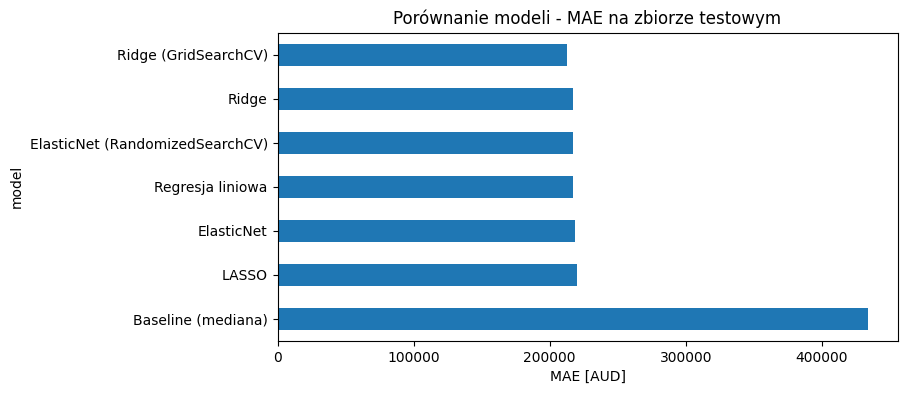

In [ ]:
results_df = pd.DataFrame(results).sort_values("test_MAE").reset_index(drop=True)
display(results_df.round(3))

ax = results_df.set_index("model")["test_MAE"].sort_values(ascending=False).plot.barh(figsize=(8, 4))
ax.set_title("Porównanie modeli - MAE na zbiorze testowym")
ax.set_xlabel("MAE [AUD]")
plt.show()

## Podsumowanie (1 punkt)

Odpowiedz krótko:
- Który model wybrałbyś do wdrożenia i dlaczego? Czy nadaje się on do praktycznej wyceny nieruchomości?
- Jak bardzo regularyzacja poprawiła wynik względem zwykłej regresji liniowej? Dlaczego zysk jest taki (mały/duży) dla tego zbioru - weź pod uwagę liczbę próbek i liczbę cech?

**Odpowiedź:**

- Do wdrożenia wybrałbym **Ridge z `GridSearchCV`**: ma najniższy błąd testowy (MAE ≈ 213 tys. AUD, MdAPE ≈ 15,7%), a błędy treningowy i testowy są zbliżone, więc model dobrze generalizuje. Do praktycznej wyceny jednak się **nie nadaje**: typowa wycena myli się o ok. 16%, czyli o ok. 150 tys. AUD przy domu za 1 mln AUD. Może służyć tylko do zgrubnego oszacowania ceny.
- Regularyzacja poprawiła wynik **minimalnie**: MAE spadło z ok. 217,1 tys. do ok. 212,8 tys. AUD (ok. 2%), a Ridge, LASSO i ElasticNet ze stałymi hiperparametrami dały praktycznie ten sam wynik co zwykła regresja liniowa. Ta niewielka poprawa pochodzi prawdopodobnie bardziej z doboru `min_frequency` niż z samej kary, bo ElasticNet ze strojonym $\alpha$, ale stałym `min_frequency`, nie poprawił wyniku. Zysk jest mały, bo mamy ok. 13 tys. próbek treningowych i niecałe 100 cech, czyli ponad 100 obserwacji na cechę. Wagi są więc szacowane stabilnie i model nie jest przeuczony. Regularyzacja zmniejsza wariancję, a problemem jest obciążenie: model liniowy nie uchwyci nieliniowego wpływu odległości, interakcji cech ani przestrzennego wzoru cen.
---

## Zadania dodatkowe (1 punkt)

**Model nieliniowy.** Wytrenuj [`HistGradientBoostingRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) przez `make_model()` i porównaj z najlepszym modelem liniowym. Czy potwierdza to obserwacje z wykresów w części 2?


In [ ]:
# miejsce na zadanie dodatkowe

## Źródła 

- S. Raschka, Y. Liu, V. Mirjalili, *Machine Learning with PyTorch and Scikit-Learn*, Packt 2022, rozdział 9.
- Dokumentacja scikit-learn: [modele liniowe](https://scikit-learn.org/stable/modules/linear_model.html), [walidacja skrośna](https://scikit-learn.org/stable/modules/cross_validation.html), [szukanie hiperparametrów](https://scikit-learn.org/stable/modules/grid_search.html), [typowe pułapki](https://scikit-learn.org/stable/common_pitfalls.html).
- Dokumentacja `uv`: [projekty](https://docs.astral.sh/uv/guides/projects/), [praca z Jupyterem](https://docs.astral.sh/uv/guides/integration/jupyter/).
- Zbiór danych: [Melbourne Housing Snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot)